# Trabajo práctico: probabilidad y decisiones — Bank Marketing

**Estudiante:** _[Nombre y apellido]_
**Curso:** Data Science — semana 4, clase 4
**Modalidad:** individual

**Fuente de los datos:** Moro, S., Rita, P. y Cortez, P. (2014). *Bank Marketing*. UCI Machine Learning Repository.
https://doi.org/10.24432/C5K306 — Licencia CC BY 4.0. Archivo utilizado: `bank.csv` (muestra aleatoria del 10 % de `bank-full.csv`).

**Pregunta central:** ¿Qué proporción de los registros terminó en suscripción y cuánto cambia esa estimación al trabajar con distintas muestras?

Recorrido: datos → proporción observada → variabilidad → decisión.

## 1. Preparar los datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

datos = pd.read_csv("bank.csv", sep=";")
print("Dimensiones:", datos.shape)
assert datos.shape == (4521, 17), "La tabla no tiene 4.521 filas y 17 columnas"

Dimensiones: (4521, 17)


In [2]:
datos.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [3]:
datos.dtypes

age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

| Elemento | Definición para este trabajo |
|---|---|
| Unidad de análisis | un registro de cliente dentro de la campaña |
| Población registrada | los registros incluidos en `bank.csv` |
| Evento de interés, S | el registro tiene `y = "yes"` |
| Denominador | registros con un valor válido en `y` |

`bank.csv` es una muestra aleatoria del 10 % de `bank-full.csv`. En este práctico, la proporción de todo `bank.csv` será la referencia observada para comparar las muestras más pequeñas.

## 2. Revisar y describir

### Revisión inicial

In [4]:
print("Filas duplicadas:", datos.duplicated().sum())
print()
print("Valores faltantes por columna:")
print(datos.isna().sum())

Filas duplicadas: 0

Valores faltantes por columna:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [5]:
# Valores válidos en y: solo "yes" o "no"
print(datos["y"].unique())

<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str


Se observa que no hay filas duplicadas ni valores faltantes. La variable `y` solo toma los valores `yes` y `no`, por lo que los 4.521 registros son válidos para el denominador.

Nota: algunas variables categóricas usan el texto `"unknown"` para indicar información desconocida (por ejemplo `contact` o `poutcome`); no aparecen como faltantes en pandas, pero no afectan a `y` ni a `campaign`.

### Variable `y`

In [6]:
frec_abs = datos["y"].value_counts()
frec_pct = datos["y"].value_counts(normalize=True) * 100

tabla_y = pd.DataFrame({"Frecuencia absoluta": frec_abs,
                        "Porcentaje (%)": frec_pct.round(2)})
tabla_y

,Frecuencia absoluta,Porcentaje (%)
y,,
no,4000,88.48
yes,521,11.52


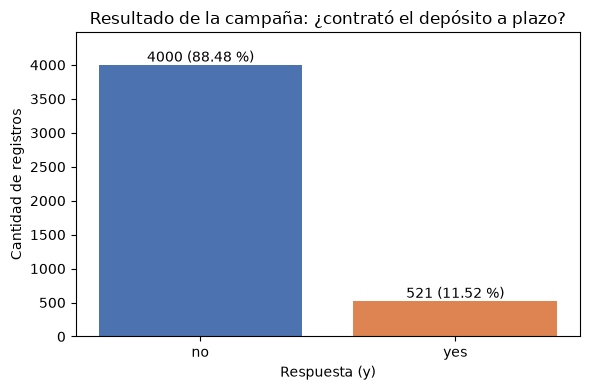

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(frec_abs.index, frec_abs.values, color=["#4C72B0", "#DD8452"])
ax.bar_label(barras, labels=[f"{n} ({p:.2f} %)" for n, p in zip(frec_abs, frec_pct)])
ax.set_title("Resultado de la campaña: ¿contrató el depósito a plazo?")
ax.set_xlabel("Respuesta (y)")
ax.set_ylabel("Cantidad de registros")
ax.set_ylim(0, frec_abs.max() * 1.12)
plt.tight_layout()
plt.show()

### Variable `campaign`

In [8]:
resumen_campaign = pd.Series({
    "Mínimo": datos["campaign"].min(),
    "Primer cuartil (Q1)": datos["campaign"].quantile(0.25),
    "Mediana": datos["campaign"].median(),
    "Tercer cuartil (Q3)": datos["campaign"].quantile(0.75),
    "Máximo": datos["campaign"].max(),
})
resumen_campaign

Mínimo                  1.0
Primer cuartil (Q1)     1.0
Mediana                 2.0
Tercer cuartil (Q3)     3.0
Máximo                 50.0
dtype: float64

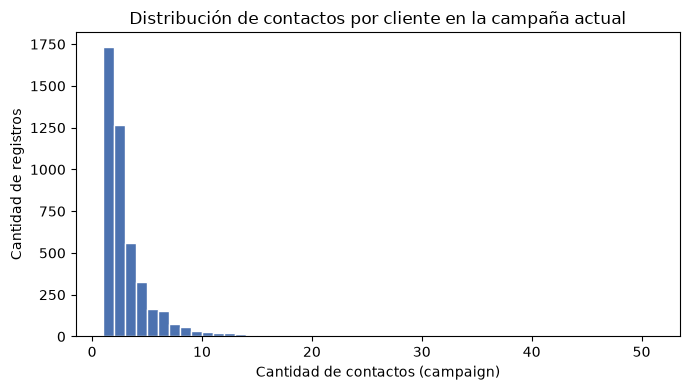

Registros con más de 10 contactos: 130


In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(datos["campaign"], bins=range(1, datos["campaign"].max() + 2),
        color="#4C72B0", edgecolor="white")
ax.set_title("Distribución de contactos por cliente en la campaña actual")
ax.set_xlabel("Cantidad de contactos (campaign)")
ax.set_ylabel("Cantidad de registros")
plt.tight_layout()
plt.show()

print("Registros con más de 10 contactos:", (datos["campaign"] > 10).sum())

**Forma de la distribución:** se observa una distribución fuertemente asimétrica a la derecha: la mitad de los registros tuvo 1 o 2 contactos (mediana = 2) y el 75 % tuvo 3 contactos o menos, pero hay una cola larga de valores altos poco frecuentes (130 registros con más de 10 contactos), que llega a un máximo de 50 contactos para un mismo cliente.

## 3. Calcular la proporción observada

In [10]:
n_validos = datos["y"].isin(["yes", "no"]).sum()
n_yes = (datos["y"] == "yes").sum()
n_no = n_validos - n_yes

p_s = n_yes / n_validos
p_sc = 1 - p_s

print(f"P(S)   = {n_yes} / {n_validos} = {p_s:.4f} = {p_s:.2%}")
print(f"P(S^c) = 1 - P(S) = {n_no} / {n_validos} = {p_sc:.4f} = {p_sc:.2%}")
print(f"P(S) + P(S^c) = {p_s + p_sc}")
assert abs(p_s + p_sc - 1) < 1e-12

P(S)   = 521 / 4521 = 0.1152 = 11.52%
P(S^c) = 1 - P(S) = 4000 / 4521 = 0.8848 = 88.48%
P(S) + P(S^c) = 1.0


Se observa que 521 de los 4.521 registros terminaron en suscripción: **P(S) = 521 / 4521 ≈ 0,1152 = 11,52 %**.
El complemento es **P(Sᶜ) = 4000 / 4521 ≈ 0,8848 = 88,48 %**. Ambas proporciones suman 1.

## 4. Observar la variabilidad entre muestras

In [11]:
filas = []
for semilla in [1, 2, 3, 4, 5]:
    muestra = datos.sample(n=300, replace=False, random_state=semilla)
    suscripciones = (muestra["y"] == "yes").sum()
    filas.append({"Semilla": semilla,
                  "Suscripciones": suscripciones,
                  "Tamaño de muestra": len(muestra),
                  "Proporción": suscripciones / len(muestra)})

tabla_muestras = pd.DataFrame(filas)
tabla_muestras["Diferencia con P(S)"] = (tabla_muestras["Proporción"] - p_s)
tabla_muestras.style.format({"Proporción": "{:.4f}", "Diferencia con P(S)": "{:+.4f}"}).hide(axis="index")

Semilla,Suscripciones,Tamaño de muestra,Proporción,Diferencia con P(S)
1,41,300,0.1367,+0.0214
2,28,300,0.0933,-0.0219
3,26,300,0.0867,-0.0286
4,31,300,0.1033,-0.0119
5,31,300,0.1033,-0.0119


In [12]:
p_min = tabla_muestras["Proporción"].min()
p_max = tabla_muestras["Proporción"].max()
dist = (tabla_muestras["Proporción"] - p_s).abs()
mas_cercanas = tabla_muestras.loc[dist == dist.min(), "Semilla"].tolist()

print(f"Proporción mínima: {p_min:.4f} ({p_min:.2%}) — semilla {tabla_muestras.loc[tabla_muestras['Proporción'].idxmin(), 'Semilla']}")
print(f"Proporción máxima: {p_max:.4f} ({p_max:.2%}) — semilla {tabla_muestras.loc[tabla_muestras['Proporción'].idxmax(), 'Semilla']}")
print(f"Diferencia (rango): {p_max - p_min:.4f} ({(p_max - p_min) * 100:.2f} puntos porcentuales)")
print(f"Muestra(s) más cercana(s) a P(S) = {p_s:.4f}: semilla(s) {mas_cercanas}, a {dist.min():.4f}")

Proporción mínima: 0.0867 (8.67%) — semilla 3
Proporción máxima: 0.1367 (13.67%) — semilla 1
Diferencia (rango): 0.0500 (5.00 puntos porcentuales)
Muestra(s) más cercana(s) a P(S) = 0.1152: semilla(s) [4, 5], a 0.0119


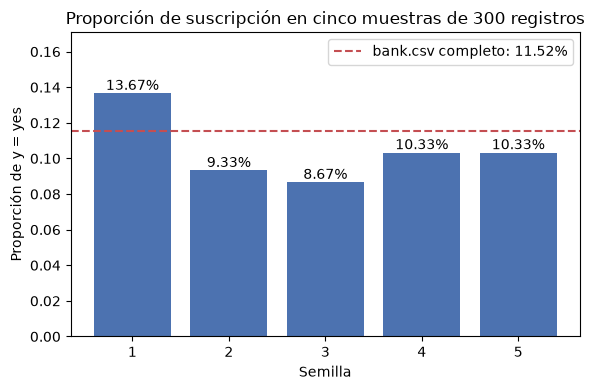

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(tabla_muestras["Semilla"].astype(str), tabla_muestras["Proporción"], color="#4C72B0")
ax.bar_label(barras, labels=[f"{p:.2%}" for p in tabla_muestras["Proporción"]])
ax.axhline(p_s, color="#C44E52", linestyle="--", label=f"bank.csv completo: {p_s:.2%}")
ax.set_title("Proporción de suscripción en cinco muestras de 300 registros")
ax.set_xlabel("Semilla")
ax.set_ylabel("Proporción de y = yes")
ax.set_ylim(0, p_max * 1.25)
ax.legend()
plt.tight_layout()
plt.show()

**Respuestas**

1. La proporción mínima fue **26 / 300 ≈ 0,0867 (8,67 %)** con la semilla 3, y la máxima fue **41 / 300 ≈ 0,1367 (13,67 %)** con la semilla 1.
2. La diferencia entre ambas es de **0,05 (5 puntos porcentuales)**, es decir, 15 suscripciones más en una muestra que en la otra.
3. Las muestras con semillas **4 y 5** quedaron empatadas como las más cercanas: ambas registran 31 / 300 ≈ 0,1033 (10,33 %), a unos 1,19 puntos porcentuales de la proporción observada en todo `bank.csv` (11,52 %).
4. Las estimaciones difieren porque cada semilla selecciona un subconjunto distinto de 300 registros al azar. Como solo alrededor de 1 de cada 9 registros es una suscripción, el número de `yes` que "cae" en cada muestra varía por azar (variabilidad muestral). Con muestras de 300 registros, unas pocas suscripciones de más o de menos mueven la proporción varios puntos: cada registro pesa 1/300 ≈ 0,33 puntos porcentuales. Con muestras más grandes esa variación sería menor.

## 5. Tomar una decisión sencilla

In [14]:
costo_contacto = 1
beneficio_suscripcion = 12

valor_esperado = beneficio_suscripcion * p_s - costo_contacto
n_piloto = 100
valor_esperado_piloto = n_piloto * valor_esperado

print(f"Beneficio esperado por contacto: 12 × {p_s:.4f} = {beneficio_suscripcion * p_s:.4f} unidades")
print(f"Valor esperado neto por contacto: 12 × {p_s:.4f} - 1 = {valor_esperado:.4f} unidades")
print(f"Valor esperado neto para {n_piloto} contactos: {n_piloto} × {valor_esperado:.4f} = {valor_esperado_piloto:.2f} unidades")

# Proporción mínima necesaria para no perder (punto de equilibrio)
p_equilibrio = costo_contacto / beneficio_suscripcion
print(f"Proporción de equilibrio: 1 / 12 = {p_equilibrio:.4f} ({p_equilibrio:.2%})")

Beneficio esperado por contacto: 12 × 0.1152 = 1.3829 unidades
Valor esperado neto por contacto: 12 × 0.1152 - 1 = 0.3829 unidades
Valor esperado neto para 100 contactos: 100 × 0.3829 = 38.29 unidades
Proporción de equilibrio: 1 / 12 = 0.0833 (8.33%)


1. **Valor esperado neto por contacto:** 12 × 0,1152 − 1 ≈ **0,38 unidades**. Si la proporción de suscripción se mantuviera como en los registros analizados, cada contacto dejaría en promedio una ganancia de unas 0,38 unidades: el beneficio esperado (≈ 1,38) supera el costo del contacto (1).
2. **Piloto de 100 contactos:** 100 × 0,3829 ≈ **38,29 unidades** de valor esperado neto.
3. **Decisión:** sí realizaría la prueba piloto, porque el valor esperado es positivo. La campaña deja de ser rentable si la proporción de suscripción cae por debajo de 1/12 ≈ 8,33 % (punto de equilibrio). Se observa que la proporción de referencia (11,52 %) está por encima de ese umbral, y cuatro de las cinco muestras de 300 también lo están; sin embargo, la semilla 3 (8,67 %) quedó muy cerca del límite. Esto muestra que el resultado no está garantizado y justifica hacer primero un piloto acotado de 100 contactos antes de escalar la campaña.

## 6. Cierre

1. **Proporción observada:** en los registros de `bank.csv` se observa que **521 / 4521 ≈ 0,1152 = 11,52 %** terminaron en suscripción (y 4000 / 4521 ≈ 88,48 % no).
2. **Variación entre muestras:** en las cinco muestras de 300 registros la proporción fue de **8,67 % a 13,67 %**, una diferencia de 5 puntos porcentuales; las muestras indican que con 300 registros la estimación puede alejarse varios puntos de la referencia sólo por azar.
3. **Decisión:** se propone realizar el piloto de 100 contactos, con un valor esperado neto de ≈ **+38,3 unidades** (≈ 0,38 por contacto). El supuesto principal es que la proporción de suscripción de la campaña futura será similar a la observada en `bank.csv` (y, en particular, superior al 8,33 % de equilibrio), además de que el costo (1) y el beneficio (12) del escenario didáctico se mantengan.